In [2]:
import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from skimage import data, img_as_float
from skimage import exposure


In [3]:
# Read the image
image = cv2.imread('images/Parrot.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB

# Gaussian sigma
sigma=2

#parameter
amount=1.5

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)
# Plot original, blurred, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(blurred)
ax[1].set_title("Blurred Image")
ax[1].axis("off")

ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")
ax[2].axis("off")

plt.show()


error: OpenCV(4.12.0) C:\miniconda3\conda-bld\opencv-suite_1764690164812\work\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


task1

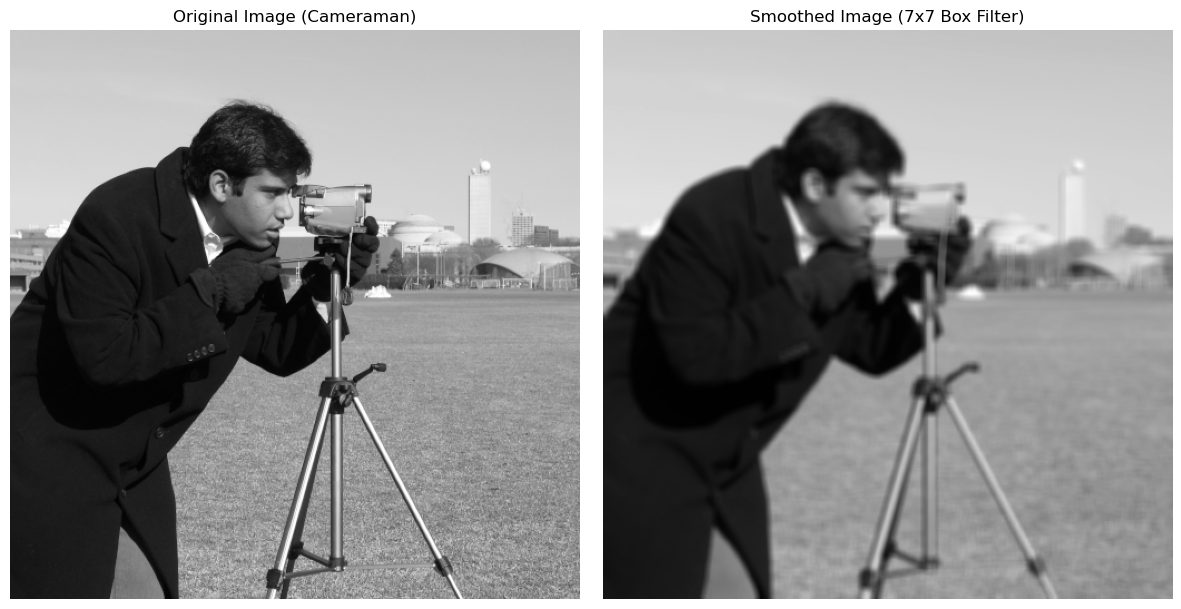

In [4]:

# 1. Load the cameraman image in grayscale
image = data.camera()

# 2. Apply a 7x7 box filter using cv2.blur
smoothed_box = cv2.blur(image, (7, 7))

# 3. Plot original and smoothed images side by side
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image (Cameraman)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(smoothed_box, cmap="gray")
plt.title("Smoothed Image (7x7 Box Filter)")
plt.axis("off")

plt.tight_layout()
plt.show()

task2

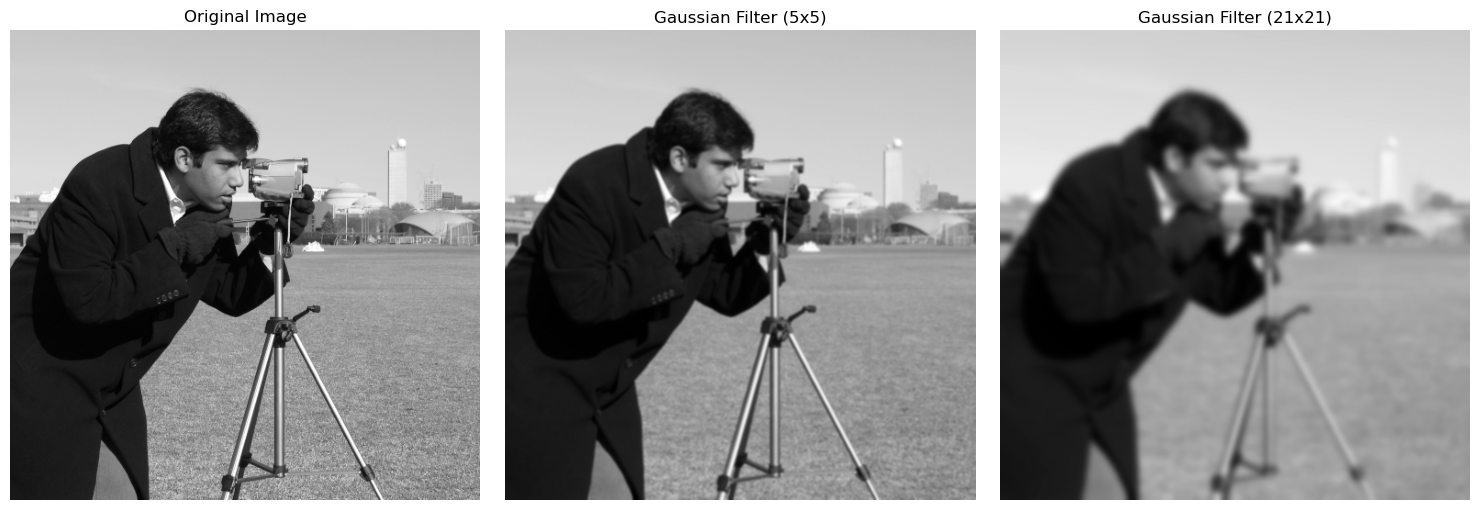

In [ ]:


# 1. Load the image
image = data.camera()

# 2. Apply a 5x5 Gaussian filter (sigma is calculated automatically if 0)
gaussian_5x5 = cv2.GaussianBlur(image, (5, 5), 0)

# 3. Apply a 21x21 Gaussian filter for stronger blurring
gaussian_21x21 = cv2.GaussianBlur(image, (21, 21), 0)

# 4. Plot the three images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_5x5, cmap="gray")
plt.title("Gaussian Filter (5x5)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_21x21, cmap="gray")
plt.title("Gaussian Filter (21x21)")
plt.axis("off")

plt.tight_layout()
plt.show()


task3

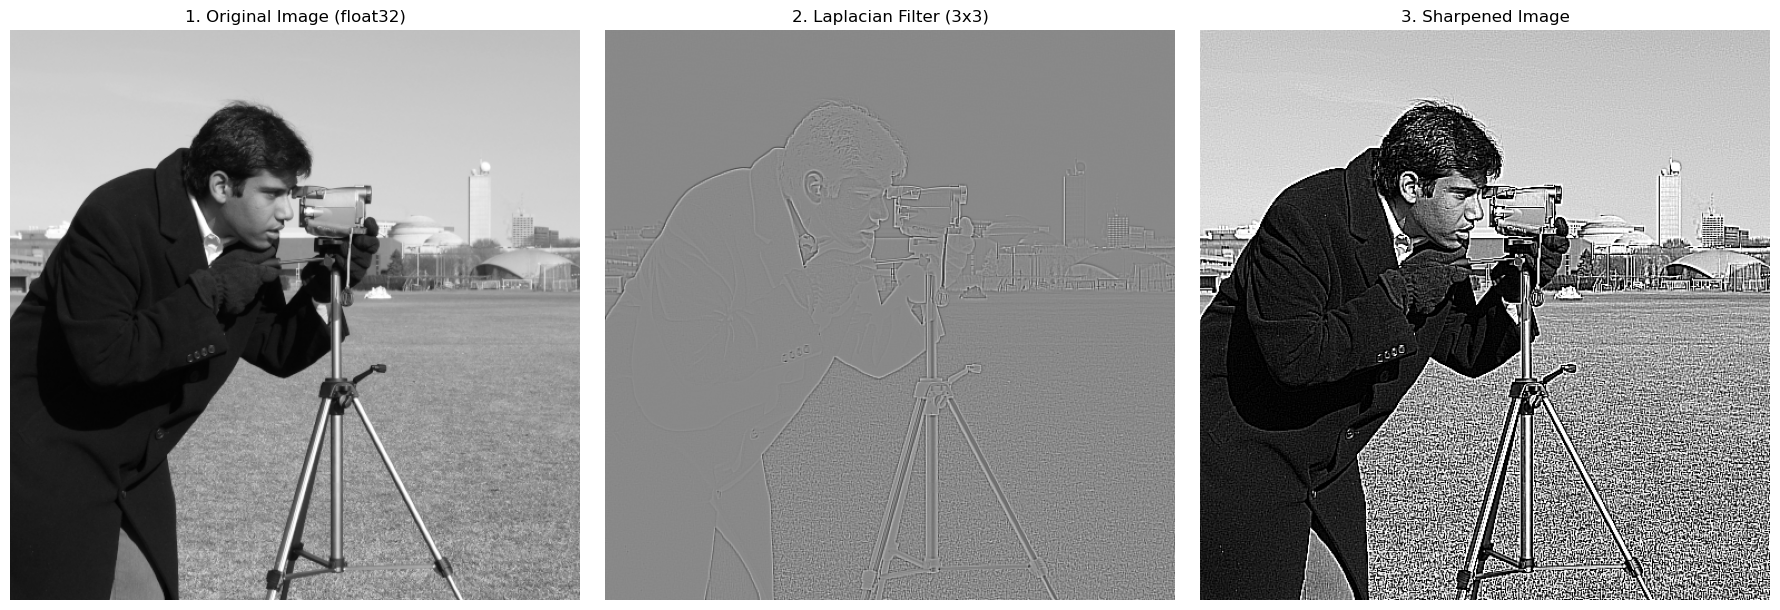

In [6]:


# Step 1: Read the image
image = data.camera()

# Step 2: Convert image to float32 and scale to [0, 1] range
image_float = image.astype(np.float32) / 255.0

# Step 3: Use the cv2.Laplacian() function with CV_32F depth for float precision
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=3)

# Step 4: Sharpen the image using the specified formula and clip values to valid [0, 1] range
sharpened = np.clip(image_float - laplacian, 0, 1)

# Step 5: Plot the original image, Laplacian result, and sharpened image
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(image_float, cmap="gray")
plt.title("1. Original Image (float32)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    laplacian, cmap="gray"
)  # Note: Can contain negative values, matplotlib handles scaling
plt.title("2. Laplacian Filter (3x3)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened, cmap="gray")
plt.title("3. Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()